# Error analysis and robustness #
Material for the report section *Error Analysis and Robustness*. Combines the saved test forecasts of every model that
has been run (`xgboost.ipynb`, `neural_network.ipynb`, `lstm.ipynb`, `local_vs_global.ipynb`) on the same 10,495 test
hours and breaks the errors down by price area, hour, week, temperature and over time. *Local heads* are the neural
network's convolutions with one dense head per location (see `local_vs_global.ipynb`); its global variant is the
*Neural network* itself. Feature importance and temperature-noise sensitivity are computed in the model notebooks (they
need the trained models) and only plotted here. The test period (20 Jan - 3 Apr 2023) has no public holidays, so
holidays are scored on the validation windows (4 Dec - 14 Jan).

Figures are saved to `figures/` as PDF for `\includegraphics`.

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from forecast_checks import ForecastValidator, MakeTrainingData, load_tables

RESULTS, FIGURES = Path("results"), Path("figures")
FIGURES.mkdir(exist_ok=True)
MODELS = {"XGBoost": "xgboost", "Neural network": "neural_network", "LSTM": "lstm", "Local heads": "local_vs_global"}
AREAS = {"oslo": "NO1 Oslo", "stavanger": "NO2 Stavanger", "trondheim": "NO3 Trondheim", "tromsø": "NO4 Tromsø",
         "bergen": "NO5 Bergen", "helsingfors": "FI Helsingfors"}


def combine(suffix: str) -> ForecastValidator:
    """One validator with the baseline and every model whose results/<model><suffix>.json exists."""
    paths = {name: RESULTS / f"{stem}{suffix}.json" for name, stem in MODELS.items()}
    missing = [name for name, path in paths.items() if not path.exists()]
    if missing:
        print(f"Not run yet, left out: {missing}")
    loaded = {name: ForecastValidator.load_predictions(path) for name, path in paths.items() if path.exists()}
    if not loaded:
        raise FileNotFoundError(f"No results/*{suffix}.json; run the model notebooks first")
    combined = next(iter(loaded.values()))
    for name, validator in loaded.items():
        if name not in combined.forecasts:
            combined.add(name, validator.forecasts[name])   #add checks that the models were scored on the same hours
    #Other forecasts saved alongside (the global CNN in local_vs_global, which is the neural network) are left out
    combined.forecasts = {name: f for name, f in combined.forecasts.items() if name in MODELS or name == combined.baseline}
    combined.groups = combined.groups.map(AREAS).rename("Price area")
    return combined


test = combine("_predictions")
df = MakeTrainingData().df
info = df.loc[test.actual.index]
assert (info["location"].astype(str).map(AREAS) == test.groups).all()
print(f"{len(info)} test hours, {info['date'].min().date()} - {info['date'].max().date()}")
test.summary(skill=True)

Not run yet, left out: ['Neural network']
10495 test hours, 2023-01-20 - 2023-04-03


,mae,rmse,nmae,bias,skill
Same hour last week,0.494720,0.806999,8.983281,0.033943,0.000000
XGBoost,0.333901,0.523908,6.063085,0.152820,0.325070
LSTM,0.283851,0.415407,5.154250,0.008411,0.426240
Local heads,0.295141,0.459356,5.359266,-0.180956,0.403418


## Per price area (table) ##
MAE in MW, and nMAE (MAE in % of consumption) so areas of different size are comparable.

In [2]:
per_area = test.per_group()
overall = test.summary().rename_axis("model").assign(group="All").set_index("group", append=True)
per_area_table = pd.concat([per_area, overall])[["mae", "nmae"]].unstack("model").reindex([*AREAS.values(), "All"])
per_area_table = per_area_table.reindex(columns=list(test.forecasts), level="model")
per_area_table.round(2)

mae                                           \
model          Same hour last week XGBoost Neural network  LSTM Local heads   
group                                                                         
NO1 Oslo                      1.30    0.84           0.58  0.62        0.78   
NO2 Stavanger                 0.59    0.47           0.31  0.37        0.29   
NO3 Trondheim                 0.41    0.23           0.17  0.22        0.20   
NO4 Tromsø                    0.18    0.11           0.10  0.09        0.12   
NO5 Bergen                    0.35    0.20           0.16  0.22        0.19   
FI Helsingfors                0.14    0.16           0.22  0.19        0.19   
All                           0.49    0.33           0.26  0.28        0.30   

                              nmae                                           
model          Same hour last week XGBoost Neural network  LSTM Local heads  
group                                                                        
NO1 Oslo                     10.67    6.92           4.73  5.04        6.35  
NO2 Stavanger                10.51    8.24           5.42  6.57        5.12  
NO3 Trondheim                11.25    6.27           4.65  5.99        5.67  
NO4 Tromsø                    9.41    5.81           5.43  4.54        6.11  
NO5 Bergen                   10.77    6.08           4.99  6.76        6.03  
FI Helsingfors                2.12    2.47           3.51  3.02        2.95  
All                           8.98    6.06           4.67  5.15        5.36

In [3]:
print(per_area_table.to_latex(float_format="%.2f"))

\begin{tabular}{lrrrrrrrrrr}
\toprule
 & \multicolumn{5}{r}{mae} & \multicolumn{5}{r}{nmae} \\
model & Same hour last week & XGBoost & Neural network & LSTM & Local heads & Same hour last week & XGBoost & Neural network & LSTM & Local heads \\
group &  &  &  &  &  &  &  &  &  &  \\
\midrule
NO1 Oslo & 1.30 & 0.84 & 0.58 & 0.62 & 0.78 & 10.67 & 6.92 & 4.73 & 5.04 & 6.35 \\
NO2 Stavanger & 0.59 & 0.47 & 0.31 & 0.37 & 0.29 & 10.51 & 8.24 & 5.42 & 6.57 & 5.12 \\
NO3 Trondheim & 0.41 & 0.23 & 0.17 & 0.22 & 0.20 & 11.25 & 6.27 & 4.65 & 5.99 & 5.67 \\
NO4 Tromsø & 0.18 & 0.11 & 0.10 & 0.09 & 0.12 & 9.41 & 5.81 & 5.43 & 4.54 & 6.11 \\
NO5 Bergen & 0.35 & 0.20 & 0.16 & 0.22 & 0.19 & 10.77 & 6.08 & 4.99 & 6.76 & 6.03 \\
FI Helsingfors & 0.14 & 0.16 & 0.22 & 0.19 & 0.19 & 2.12 & 2.47 & 3.51 & 3.02 & 2.95 \\
All & 0.49 & 0.33 & 0.26 & 0.28 & 0.30 & 8.98 & 6.06 & 4.67 & 5.15 & 5.36 \\
\bottomrule
\end{tabular}



## By hour of day and by weekday ##
nMAE rather than MAE, so Oslo (about 6 times the consumption of Tromsø) does not dominate.

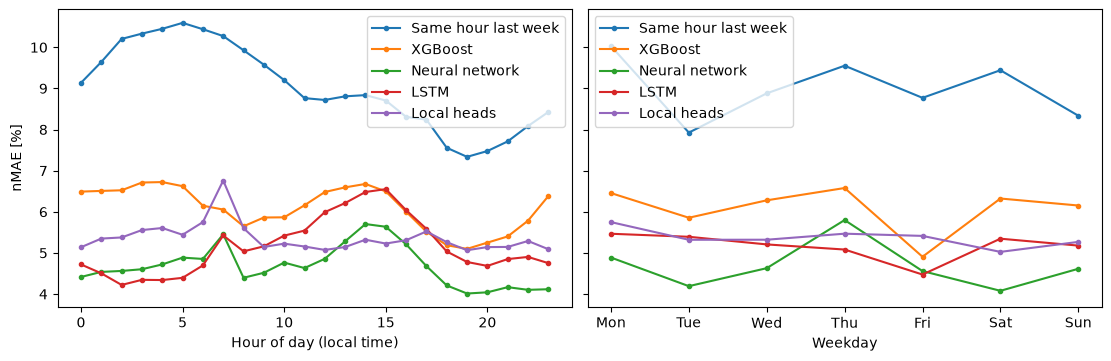

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True, layout="constrained")
test.plot_metric_by(info["hour"].rename("Hour of day (local time)"), ax=axes[0])
#From the local date, so it matches the local hour on the left. Ordered Monday - Sunday, not alphabetically
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = pd.Series(pd.Categorical.from_codes(info["date"].dt.dayofweek, categories=DAYS), index=info.index,
                    name="Weekday")
test.plot_metric_by(weekday, ax=axes[1])
fig.savefig(FIGURES / "error_by_hour_and_weekday.pdf")

## Cold spells ##
Days are ranked by their mean temperature within each location (decile 1 = the coldest 10 % of test days there), so cold
spells in all areas are compared despite their different climates.

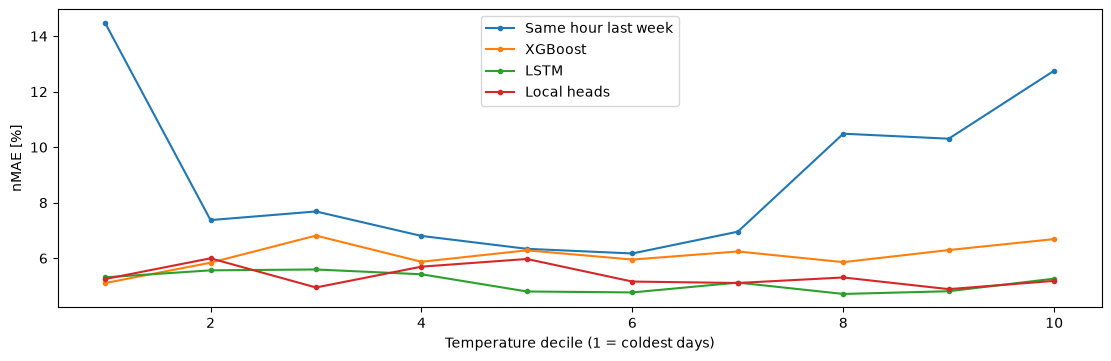

In [14]:
daily_temperature = info.groupby(["location", "date"], observed=True)["temperature"].transform("mean")
decile = (daily_temperature.groupby(info["location"], observed=True)
          .transform(lambda t: pd.qcut(t.rank(method="dense"), 10, labels=False) + 1)
          .rename("Temperature decile (1 = coldest days)"))
fig, axes = plt.subplots(1, 1, figsize=(11, 3.5), layout="constrained")
test.plot_metric_by(decile, ax=axes)
fig.savefig(FIGURES / "error_by_temperature.pdf")

In [6]:
cold_spell = (decile == 1).map({True: "Coldest 10 % of days", False: "Other days"}).rename("period")
test.per(cold_spell, skill=True)

mae      rmse       nmae  \
model               period                                                
Same hour last week Coldest 10 % of days  0.891356  1.314524  14.476407   
                    Other days            0.445815  0.720060   8.214823   
XGBoost             Coldest 10 % of days  0.314351  0.467282   5.105330   
                    Other days            0.336312  0.530472   6.197070   
Neural network      Coldest 10 % of days  0.272851  0.425760   4.431341   
                    Other days            0.255060  0.372153   4.699874   
LSTM                Coldest 10 % of days  0.327103  0.504345   5.312436   
                    Other days            0.278518  0.403085   5.132120   
Local heads         Coldest 10 % of days  0.323262  0.553749   5.250052   
                    Other days            0.291674  0.446337   5.374545   

                                              bias     skill  
model               period                                    
Same hour last week Coldest 10 % of days -0.880345  0.000000  
                    Other days            0.146675  0.000000  
XGBoost             Coldest 10 % of days  0.012315  0.647334  
                    Other days            0.170144  0.245623  
Neural network      Coldest 10 % of days -0.089272  0.693892  
                    Other days            0.009298  0.427879  
LSTM                Coldest 10 % of days -0.018950  0.633028  
                    Other days            0.011784  0.375261  
Local heads         Coldest 10 % of days -0.191008  0.637337  
                    Other days           -0.179717  0.345750

## Bias over time: portfolio level shifts ##
A curve that stays away from 0 for weeks means the level of the area has changed (e.g. customers gained or lost), which
consumption lags that are at least 6 days old cannot catch up with immediately.

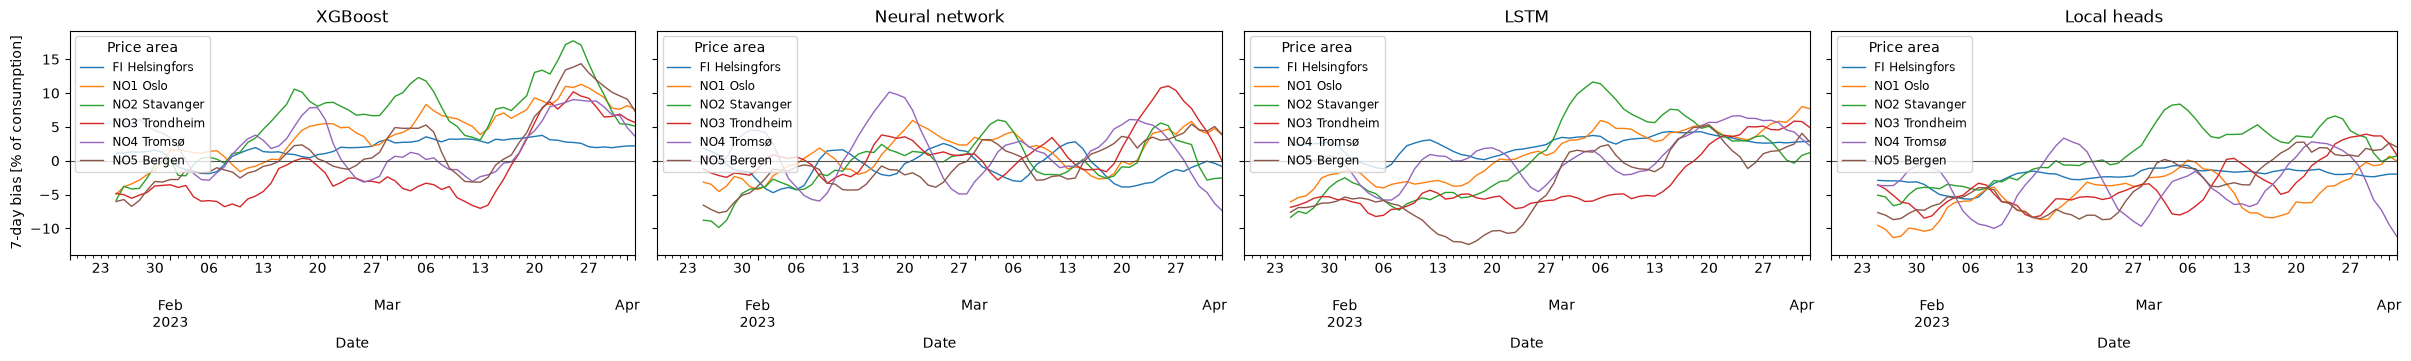

In [7]:
fig = test.plot_rolling_bias(info["time"])
fig.savefig(FIGURES / "rolling_bias.pdf")

## Feature importance and temperature forecast error ##
Left: increase in test MAE when a group of inputs is shuffled within each location. Right: increase in test MAE when a
day-ahead temperature forecast error with the given standard deviation is added (our temperature is reanalysis data,
i.e. close to the real weather).

XGBoost  Neural network       LSTM
importance [%]        consumption    24.498970      124.456268  24.386612
                      temperature    57.660913      131.898496  96.245150
                      calendar       30.080866        5.847136  53.396315
                      other weather   1.311597        4.149717   4.701469
temperature noise [%] 0.0             0.000000        0.000000   0.000000
                      0.5             1.405158        0.768232   1.331960
                      1.0             3.897542        2.751663   4.639882
                      2.0            10.495964        9.393451  12.959033
                      3.0            16.956862       18.225456  30.011013

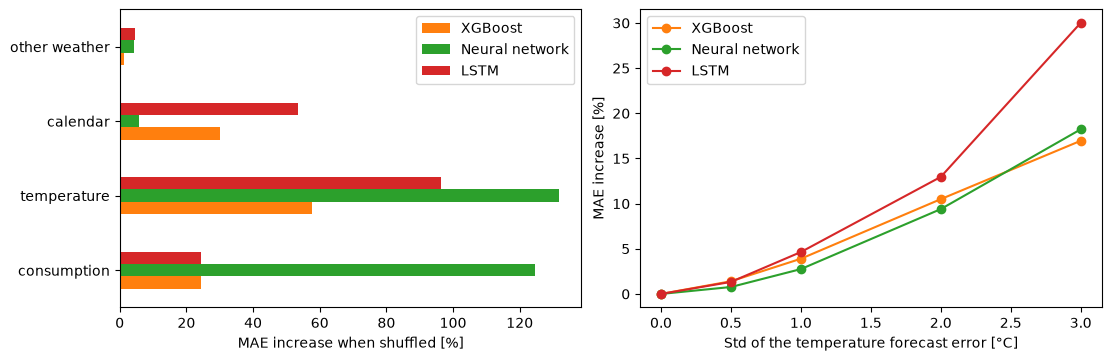

In [8]:
robustness = {name: load_tables(RESULTS / f"{stem}_robustness.json") for name, stem in MODELS.items()
              if (RESULTS / f"{stem}_robustness.json").exists()}
importance = pd.DataFrame({name: tables["importance"]["relative_increase"] for name, tables in robustness.items()})
temperature_noise = pd.DataFrame({name: tables["temperature_noise"]["relative_increase"] for name, tables in robustness.items()})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
importance.plot.barh(ax=axes[0], color=test.colors(importance.columns))
axes[0].set_xlabel("MAE increase when shuffled [%]")
axes[0].set_ylabel("")
temperature_noise.plot(ax=axes[1], marker="o", color=test.colors(temperature_noise.columns))
axes[1].set_xlabel("Std of the temperature forecast error [°C]")
axes[1].set_ylabel("MAE increase [%]")
fig.savefig(FIGURES / "importance_and_temperature_noise.pdf")
pd.concat({"importance [%]": importance, "temperature noise [%]": temperature_noise})

## Holidays (validation windows) ##
The test period has no public holidays, so Christmas and New Year are scored on the validation windows (4 Dec - 14 Jan),
with each model fitted only on data up to 6 days before each window. Note that the neural network and the LSTM chose
their hyperparameters, and the local heads their number of epochs, on these windows, so their validation scores are
slightly optimistic compared with XGBoost's.

In [9]:
val = combine("_validation_predictions")
val_info = df.loc[val.actual.index]
CHRISTMAS = ("2022-12-24", "2023-01-01")
period = (val_info["date"].between(*CHRISTMAS)
          .map({True: "Christmas and New Year (24 Dec - 1 Jan)", False: "Other validation days"}).rename("period"))
val.per(period, skill=True)

mae  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.532187   
                    Other validation days                    0.838910   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.580820   
                    Other validation days                    0.637206   
Neural network      Christmas and New Year (24 Dec - 1 Jan)  0.390095   
                    Other validation days                    0.343211   
LSTM                Christmas and New Year (24 Dec - 1 Jan)  0.385428   
                    Other validation days                    0.349784   
Local heads         Christmas and New Year (24 Dec - 1 Jan)  0.444829   
                    Other validation days                    0.400459   

                                                                 rmse  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.881321   
                    Other validation days                    1.282444   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.863406   
                    Other validation days                    1.029211   
Neural network      Christmas and New Year (24 Dec - 1 Jan)  0.533903   
                    Other validation days                    0.511983   
LSTM                Christmas and New Year (24 Dec - 1 Jan)  0.589194   
                    Other validation days                    0.531600   
Local heads         Christmas and New Year (24 Dec - 1 Jan)  0.701122   
                    Other validation days                    0.636367   

                                                                  nmae  \
model               period                                               
Same hour last week Christmas and New Year (24 Dec - 1 Jan)   9.012042   
                    Other validation days                    14.193054   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)   9.835600   
                    Other validation days                    10.780527   
Neural network      Christmas and New Year (24 Dec - 1 Jan)   6.605860   
                    Other validation days                     5.806586   
LSTM                Christmas and New Year (24 Dec - 1 Jan)   6.526829   
                    Other validation days                     5.917803   
Local heads         Christmas and New Year (24 Dec - 1 Jan)   7.532729   
                    Other validation days                     6.775138   

                                                                 bias  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan) -0.077304   
                    Other validation days                   -0.071839   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.243613   
                    Other validation days                    0.074458   
Neural network      Christmas and New Year (24 Dec - 1 Jan) -0.178362   
                    Other validation days                    0.051975   
LSTM                Christmas and New Year (24 Dec - 1 Jan) -0.258951   
                    Other validation days                   -0.127426   
Local heads         Christmas and New Year (24 Dec - 1 Jan) -0.336389   
                    Other validation days                    0.098090   

                                                                skill  
model               period                                             
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.000000  
                    Other validation days                    0.000000  
XGBoost             Christmas and New Year (24 Dec - 1 Jan) -0.091384  
                    Other validation days                    0.240436  
Neural network      Christmas and New Year (24 Dec - 1 Jan)  0.266996  
                    Other validation days 